# ARIMA Baseline — per ticker, univariate

Input:  `data/processed/v2/features_train.csv`\
        `data/processed/v2/features_test.csv`
Output: `data/results/arima_results.csv`   (per-row predictions)\
        `data/results/arima_summary.csv`   (per-ticker + overall metrics)

Model: ARIMA(1,0,1) per ticker on target series (next-day log return).
       Univariate — only uses past returns, no external features.
       d=0 because returns are already stationary.

Forecast strategy: fit on full train, one-shot forecast over test horizon.

In [1]:
import sys
import warnings
import numpy as np
import pandas as pd
from pathlib import Path
from statsmodels.tsa.arima.model import ARIMA

warnings.filterwarnings("ignore")

ROOT_DIR   = Path.cwd().parent.parent
TRAIN_PATH = ROOT_DIR / "data" / "processed" / "v2" / "features_train.csv"
TEST_PATH  = ROOT_DIR / "data" / "processed" / "v2" / "features_test.csv"
OUT_DIR    = ROOT_DIR / "data" / "results"
OUT_DIR.mkdir(parents=True, exist_ok=True)

ARIMA_ORDER = (1, 0, 1)

In [2]:
def eval_metrics(y_true: np.ndarray, y_pred: np.ndarray) -> dict:
    mae  = np.mean(np.abs(y_true - y_pred))
    rmse = np.sqrt(np.mean((y_true - y_pred) ** 2))
    da   = np.mean(np.sign(y_true) == np.sign(y_pred))
    ic   = np.corrcoef(y_true, y_pred)[0, 1] if np.std(y_pred) > 0 else 0.0
    return {"MAE": mae, "RMSE": rmse, "DA": da, "IC": ic}

def forecast_arima(train_y: np.ndarray, n_steps: int, ticker: str) -> np.ndarray:
    try:
        model  = ARIMA(train_y, order=ARIMA_ORDER)
        fitted = model.fit()
        preds  = fitted.forecast(steps=n_steps)
        return np.array(preds)
    except Exception as e:
        print(f"  [{ticker}] ARIMA failed ({e}) -> zero forecast")
        return np.zeros(n_steps)

In [3]:
print("=" * 60)
print(f"ARIMA BASELINE — ARIMA{ARIMA_ORDER}")
print("=" * 60)

train = pd.read_csv(TRAIN_PATH, parse_dates=["Date"])
test  = pd.read_csv(TEST_PATH,  parse_dates=["Date"])

tickers = sorted(train["ticker"].unique())
print(f"Tickers ({len(tickers)}): {tickers}")
print(f"Train rows: {len(train):,} | Test rows: {len(test):,}\n")

all_preds    = []
summary_rows = []

for ticker in tickers:
    tr = train[train["ticker"] == ticker].sort_values("Date")
    te = test[test["ticker"]  == ticker].sort_values("Date")

    train_y = tr["target"].values
    test_y  = te["target"].values

    print(f"[{ticker}] train={len(train_y)} | test={len(test_y)}", end="  ->  ")
    preds = forecast_arima(train_y, len(test_y), ticker)

    m = eval_metrics(test_y, preds)
    print(f"MAE={m['MAE']:.6f} | RMSE={m['RMSE']:.6f} | DA={m['DA']:.3f} | IC={m['IC']:.4f}")

    df_pred = te[["Date", "ticker", "target", "regime_hmm"]].copy()
    df_pred["pred"] = preds
    all_preds.append(df_pred)
    summary_rows.append({"ticker": ticker, **m})

results = pd.concat(all_preds, ignore_index=True)
results.to_csv(OUT_DIR / "arima_results.csv", index=False)

summary = pd.DataFrame(summary_rows)
overall = eval_metrics(results["target"].values, results["pred"].values)
summary.loc[len(summary)] = {"ticker": "OVERALL", **overall}
summary.to_csv(OUT_DIR / "arima_summary.csv", index=False)

print("\n" + "=" * 60)
print("ARIMA — OVERALL METRICS")
print("=" * 60)
print(summary.round(6).to_string(index=False))

print("\nPer-regime breakdown:")
for regime in ["Bull", "Sideways", "Bear"]:
    mask = results["regime_hmm"] == regime
    if mask.sum() == 0:
        continue
    m = eval_metrics(results.loc[mask, "target"].values, results.loc[mask, "pred"].values)
    print(f"  {regime:10s}: MAE={m['MAE']:.6f} | RMSE={m['RMSE']:.6f} "
          f"| DA={m['DA']:.3f} | IC={m['IC']:.4f} | n={mask.sum()}")

print(f"\nSaved: {OUT_DIR / 'arima_results.csv'}")
print(f"Saved: {OUT_DIR / 'arima_summary.csv'}")

ARIMA BASELINE — ARIMA(1, 0, 1)
Tickers (15): ['ACB', 'BVH', 'CTG', 'FPT', 'GAS', 'HPG', 'KDH', 'MBB', 'MSN', 'PDR', 'SSI', 'STB', 'VCB', 'VIC', 'VNM']
Train rows: 34,917 | Test rows: 13,140

[ACB] train=2325 | test=876  ->  MAE=0.010109 | RMSE=0.015483 | DA=0.457 | IC=0.0065
[BVH] train=2328 | test=876  ->  MAE=0.012543 | RMSE=0.018580 | DA=0.443 | IC=-0.0123
[CTG] train=2328 | test=876  ->  MAE=0.012951 | RMSE=0.018808 | DA=0.509 | IC=0.0253
[FPT] train=2328 | test=876  ->  MAE=0.011402 | RMSE=0.016248 | DA=0.493 | IC=-0.0323
[GAS] train=2328 | test=876  ->  MAE=0.010301 | RMSE=0.015341 | DA=0.426 | IC=0.0195
[HPG] train=2328 | test=876  ->  MAE=0.014358 | RMSE=0.020586 | DA=0.454 | IC=-0.0321
[KDH] train=2328 | test=876  ->  MAE=0.015042 | RMSE=0.022464 | DA=0.460 | IC=-0.0141
[MBB] train=2328 | test=876  ->  MAE=0.012235 | RMSE=0.018086 | DA=0.489 | IC=0.0122
[MSN] train=2328 | test=876  ->  MAE=0.014728 | RMSE=0.020719 | DA=0.460 | IC=0.0211
[PDR] train=2328 | test=876  ->  MAE=0.

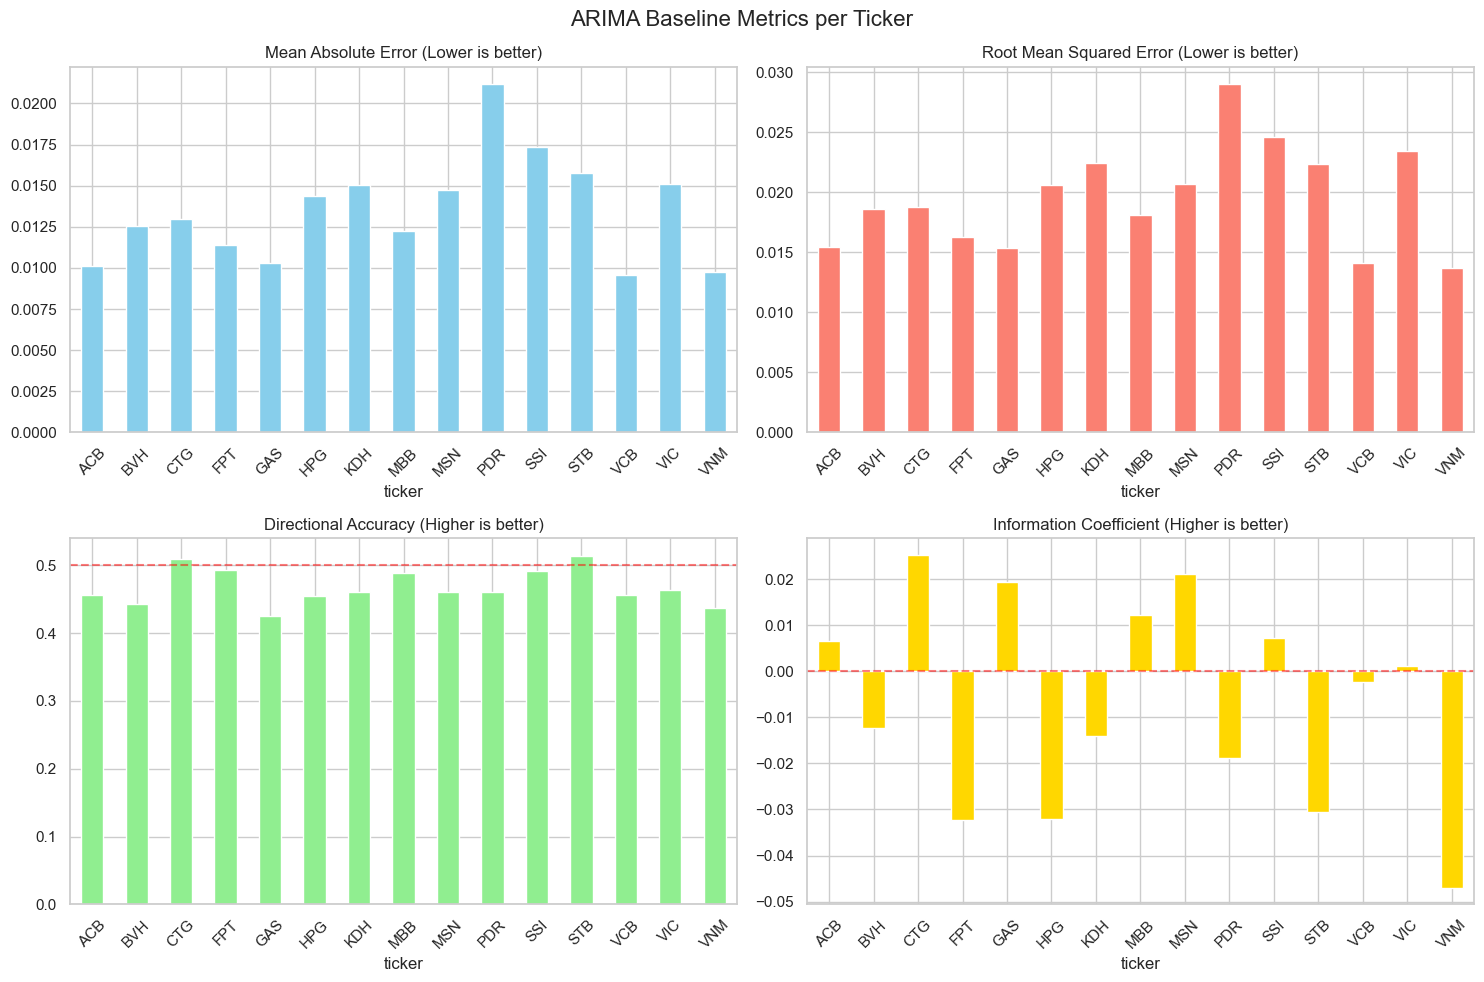

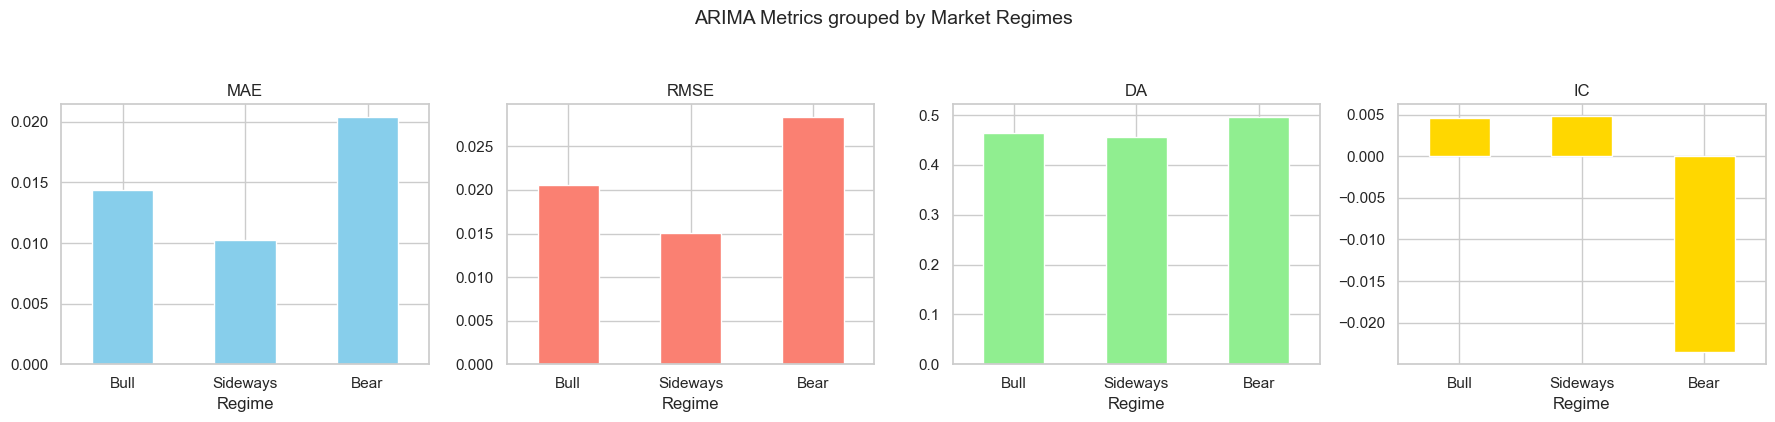

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure styling
sns.set_theme(style="whitegrid")

if 'summary' in locals():
    # Lọc bỏ row OVERALL để vẽ biểu đồ cho từng mã
    df_plot = summary[summary['ticker'] != 'OVERALL'].set_index('ticker')
    
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))
    fig.suptitle('ARIMA Baseline Metrics per Ticker', fontsize=16)
    
    # MAE
    df_plot[['MAE']].plot(kind='bar', ax=axes[0, 0], color='skyblue', legend=False)
    axes[0, 0].set_title('Mean Absolute Error (Lower is better)')
    axes[0, 0].tick_params(axis='x', rotation=45)
    
    # RMSE
    df_plot[['RMSE']].plot(kind='bar', ax=axes[0, 1], color='salmon', legend=False)
    axes[0, 1].set_title('Root Mean Squared Error (Lower is better)')
    axes[0, 1].tick_params(axis='x', rotation=45)
    
    # Directional Accuracy (DA)
    df_plot[['DA']].plot(kind='bar', ax=axes[1, 0], color='lightgreen', legend=False)
    axes[1, 0].set_title('Directional Accuracy (Higher is better)')
    axes[1, 0].axhline(0.5, color='red', linestyle='--', alpha=0.5) # Baseline random
    axes[1, 0].tick_params(axis='x', rotation=45)
    
    # Information Coefficient (IC)
    df_plot[['IC']].plot(kind='bar', ax=axes[1, 1], color='gold', legend=False)
    axes[1, 1].set_title('Information Coefficient (Higher is better)')
    axes[1, 1].axhline(0.0, color='red', linestyle='--', alpha=0.5)
    axes[1, 1].tick_params(axis='x', rotation=45)
    
    plt.tight_layout()
    plt.show()

# Visualize Market Regimes Metrics
if 'results' in locals() and 'regime_hmm' in (results.columns if 'results' in locals() else []):
    regime_list = ["Bull", "Sideways", "Bear"]
    regime_metrics = []
    for regime in regime_list:
        mask = results["regime_hmm"] == regime
        if mask.sum() > 0:
            m = eval_metrics(results.loc[mask, "target"].values, results.loc[mask, "pred"].values)
            m['Regime'] = regime
            regime_metrics.append(m)
            
    if regime_metrics:
        df_regime = pd.DataFrame(regime_metrics).set_index('Regime')
        
        fig, axes = plt.subplots(1, 4, figsize=(18, 4))
        fig.suptitle('ARIMA Metrics grouped by Market Regimes', fontsize=14, y=1.05)
        
        colors = ['skyblue', 'salmon', 'lightgreen', 'gold']
        for idx, col in enumerate(['MAE', 'RMSE', 'DA', 'IC']):
            df_regime[[col]].plot(kind='bar', ax=axes[idx], color=colors[idx], legend=False)
            axes[idx].set_title(col)
            axes[idx].tick_params(axis='x', rotation=0)
            
        plt.tight_layout()
        plt.show()

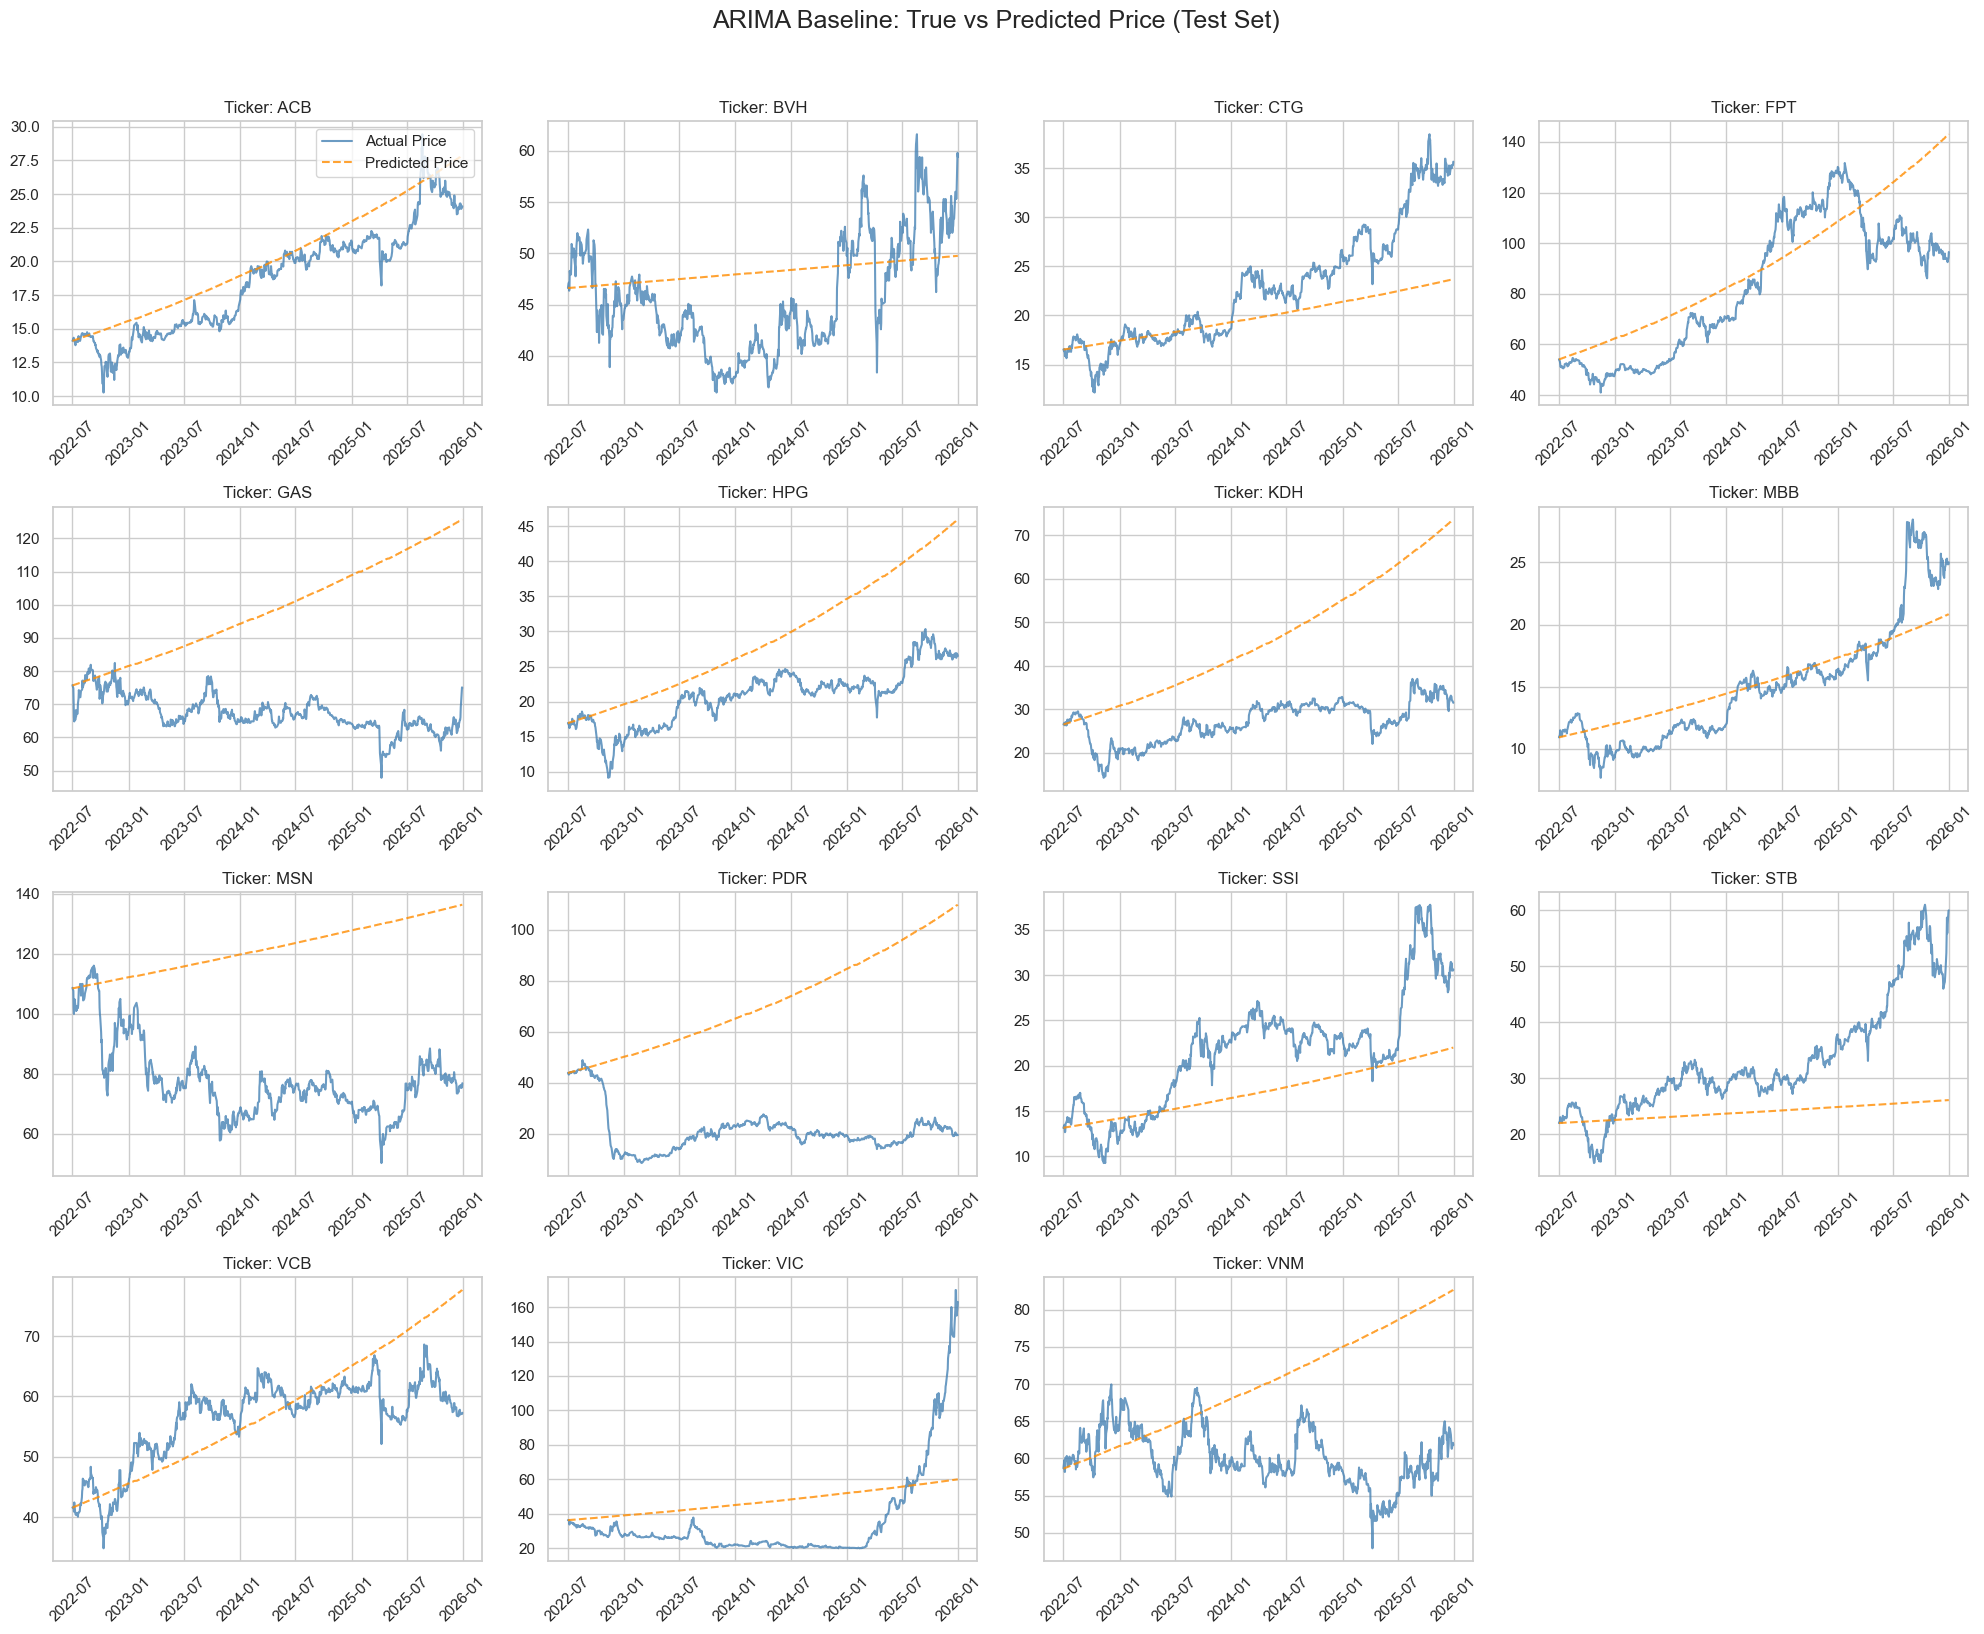

In [5]:
# Visualize True Price vs Predicted Price for each ticker
if 'results' in locals() and not results.empty and 'test' in locals():
    import matplotlib.dates as mdates
    import numpy as np
    
    unique_tickers = sorted(results['ticker'].unique())
    n_tickers = len(unique_tickers)
    
    cols = 4 # Plot 4 tickers per row
    rows = (n_tickers + cols - 1) // cols
    
    fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 4 * rows))
    if not isinstance(axes, np.ndarray):
        axes = [axes]
    else:
        axes = axes.flatten()
        
    fig.suptitle('ARIMA Baseline: True vs Predicted Price (Test Set)', fontsize=18, y=1.02)
    
    for i, ticker in enumerate(unique_tickers):
        ax = axes[i]
        
        # Lọc df theo ticker
        df_t = results[results['ticker'] == ticker].sort_values('Date').reset_index(drop=True)
        df_test_t = test[test['ticker'] == ticker].sort_values('Date').reset_index(drop=True)
        
        # Lấy giá thực tế (Close)
        actual_price = df_test_t['Close']
        
        # Tính toán giá dự đoán
        # P_pred[t] = P_true[0] * exp( sum(pred[0...t-1]) )
        p0 = actual_price.iloc[0]
        
        # dời pred đi 1 step vì pred ở t là dùng để dự phóng cho t+1
        cumulative_preds = df_t['pred'].shift(1).fillna(0).cumsum()
        pred_price = p0 * np.exp(cumulative_preds)
        
        ax.plot(df_t['Date'], actual_price, label='Actual Price', color='steelblue', alpha=0.8, linewidth=1.5)
        ax.plot(df_t['Date'], pred_price, label='Predicted Price', color='darkorange', alpha=0.8, linestyle='--', linewidth=1.5)
        
        ax.set_title(f"Ticker: {ticker}")
        ax.xaxis.set_major_locator(mdates.AutoDateLocator())
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
        ax.tick_params(axis='x', rotation=45)
        
        if i == 0:
            ax.legend(loc='upper right')
            
    # Hide any empty subplots
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])
        
    plt.tight_layout()
    plt.show()